# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/quangptt0910/flyrank-ml-internship-starter/blob/main/work/notebooks/w04_signal_audit.ipynb)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

**Lane 2 — Refresh / Content Opportunity Scoring.** Skills: `auditing-signals`, `flyrank/flyrank-data`.

**Data:** `data/raw/content_refresh_anonymized.csv` (30,000 anonymized pages, 32 clients, trailing 90-day metrics). **Outcome tested against:** `is_declining_label` = last-30-day impressions more than 20% below the previous 30 days (base rate 54.2%).

**Ground rules, fixed before looking at results:**
- Every claim is written as a common SEO belief *before* its test.
- Every rate is shown with its `n`. No verdict comes from a bucket under **50 pages** (30 for per-client cuts).
- **Verdict rule**, comparing the bucket the claim says is riskier with the one it says is safer:
  - **CONFIRMED:** gap ≥ +5 points, and the same direction holds in at least 2/3 of clients with enough data (min. 5 clients).
  - **OPPOSITE:** gap ≤ −5 points, and the reverse holds in at least 2/3 of those clients.
  - **FALSE:** |gap| < 2 points, so no meaningful difference.
  - **MIXED:** anything else, such as a gap that does not hold up client by client.
- A second slice (per client, or within the largest content type) re-checks each verdict, so a client mix effect cannot pass as a signal.

The two signals first tested inside `w04_baseline_score.ipynb` (position tier, active days) are re-run here properly. That notebook stays focused on the baseline rule.


## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

30,000 pages, 32 clients, base rate 0.542

                          count   min     50%    mean      90%      99%       max  skew  share_zero_%
impressions_90d         30000.0   1.0   731.0  5200.4  12136.4  73505.8  517715.0  11.4           0.0
clicks_90d              30000.0   0.0     1.0    16.1     32.0    253.0    4178.0  18.3          44.0
sessions_90d            30000.0   1.0     7.0    37.1     88.0    451.0    4345.0  12.1           0.0
ctr                     30000.0   0.0     0.1     0.5      0.6      8.3     100.0  17.4          44.0
avg_position            30000.0   0.0    10.8    16.3     36.8     69.9     245.0   2.0           4.0
days_with_impressions   30000.0   1.0    81.0    61.5     88.0     88.0      88.0  -0.8           0.0
word_count              22301.0   8.0  2877.0  3107.8   5327.0   7292.0    9546.0   0.9           0.0
days_since_last_update  30000.0   1.0    20.0    46.1    104.0    106.0     373.0   1.2           0.0
content_age_days        30000.0  90.0  

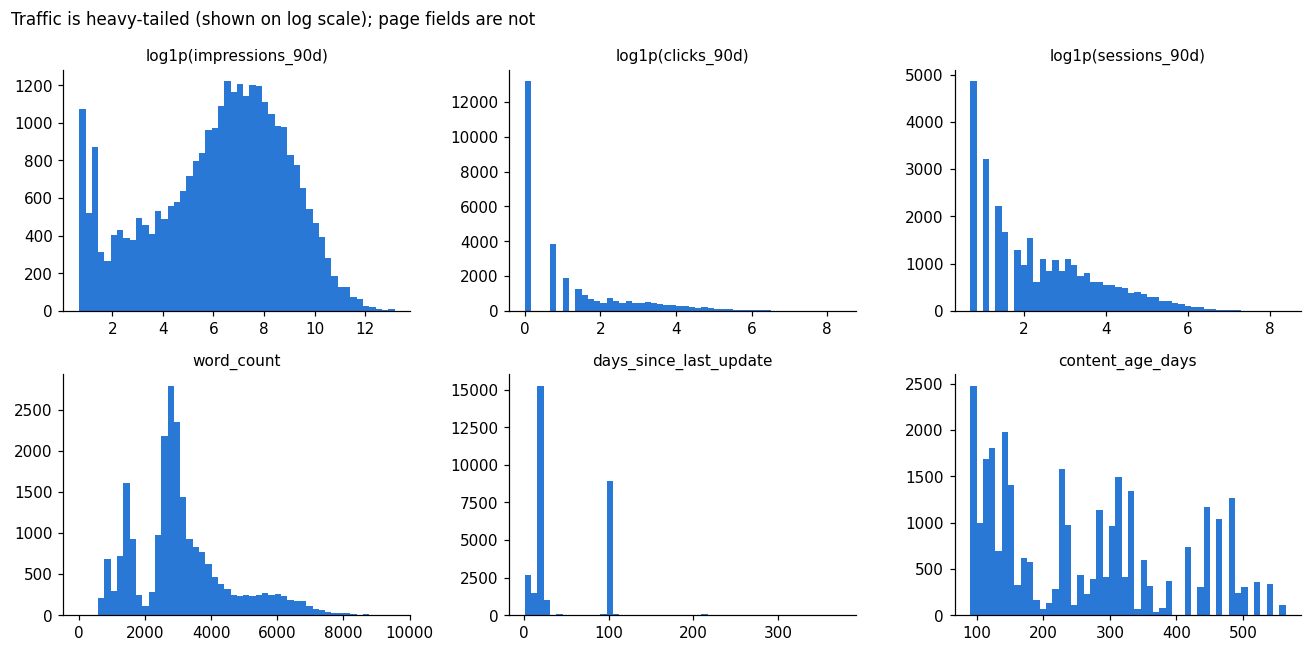

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def find(rel):
    for base in [Path("."), Path(".."), Path("../..")]:
        if (base / rel).exists():
            return base / rel
    raise FileNotFoundError(rel)

df = pd.read_csv(find("data/raw/content_refresh_anonymized.csv"))
df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)
BASE = df["is_declining_label"].mean()
print(f"{len(df):,} pages, {df['client_id'].nunique()} clients, base rate {BASE:.3f}\n")

KEY = ["impressions_90d", "clicks_90d", "sessions_90d", "ctr", "avg_position", "days_with_impressions",
       "word_count", "days_since_last_update", "content_age_days", "engagement_rate"]
desc = df[KEY].describe(percentiles=[0.5, 0.9, 0.99]).T[["count", "min", "50%", "mean", "90%", "99%", "max"]]
desc["skew"] = df[KEY].skew()
desc["share_zero_%"] = (df[KEY] == 0).mean() * 100
print(desc.round(1).to_string())

print("\nGotchas confirmed in the data:")
print(f"  - avg_position == 0 ('no position data', not rank 0): {(df['avg_position'] == 0).sum():,} pages")
print(f"  - ctr == 100% (tiny denominators):                 {(df['ctr'] >= 100).sum():,} pages, "
      f"all with impressions_90d <= {df.loc[df['ctr'] >= 100, 'impressions_90d'].max():,}")
wc_miss = df.groupby("content_type")["word_count"].apply(lambda s: s.isna().mean())
print(f"  - word_count missing:                               {df['word_count'].isna().mean():.1%} overall; by type: "
      + ", ".join(f"{k} {v:.0%}" for k, v in wc_miss.items()))

fig, axes = plt.subplots(2, 3, figsize=(12, 6), dpi=110)
for ax, col in zip(axes.flat, ["impressions_90d", "clicks_90d", "sessions_90d"]):
    ax.hist(np.log1p(df[col]), bins=50, color="#2a78d6")
    ax.set_title(f"log1p({col})", fontsize=10)
for ax, col in zip(axes.flat[3:], ["word_count", "days_since_last_update", "content_age_days"]):
    ax.hist(df[col].dropna(), bins=50, color="#2a78d6")
    ax.set_title(col, fontsize=10)
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Traffic is heavy-tailed (shown on log scale); page fields are not", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()


In [2]:
# The label itself has mechanics worth seeing before any test:
# pages with little activity are often 'new' or 'flat', which can never be 'down'.
act = pd.cut(df["days_with_impressions"], [-1, 15, 45, 75, 90],
             labels=["sparse (<=15d)", "moderate (16-45d)", "regular (46-75d)", "daily (76-90d)"])
mix = pd.crosstab(act, df["trend_direction"], normalize="index").round(2)
mix["n"] = act.value_counts()
mix["decline_rate"] = df.groupby(act, observed=True)["is_declining_label"].mean().round(3)
print("trend_direction mix by activity level:")
print(mix.to_string())


trend_direction mix by activity level:
trend_direction        down  flat   new  stable    up      n  decline_rate
days_with_impressions                                                     
sparse (<=15d)         0.28  0.20  0.37    0.06  0.08   5376         0.284
moderate (16-45d)      0.60  0.02  0.07    0.11  0.19   3612         0.605
regular (46-75d)       0.65  0.00  0.00    0.15  0.20   4360         0.651
daily (76-90d)         0.58  0.00  0.00    0.27  0.14  16652         0.583


**What the distributions say.**
- Traffic is extremely heavy-tailed: median 731 impressions, 99th percentile 73,506, maximum about 518,000. Every traffic comparison below uses tiers or log scale, never raw means.
- CTR hits 100% only on 11 pages, each with a single impression, so it is a ratio with tiny denominators. `avg_position = 0` means "no data" on 1,205 pages, and `word_count` is missing for 28% of keyword articles but never for the other types, so missing values follow content type.
- **Label mechanics.** Only 28% of sparse pages are "down", but 57% of them are "new" or "flat", labels that can never be "down". The original W04 active-days test (MIXED) mostly measured this mechanic, not a decay signal. Any test that touches activity has to keep it in mind.


## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

In [3]:
FLOOR, CLIENT_FLOOR, MIN_CLIENTS = 50, 30, 5

def rate_table(data, bucket):
    t = data.groupby(bucket, observed=True)["is_declining_label"].agg(n="size", decline_rate="mean")
    t["vs_base_pts"] = (t["decline_rate"] - BASE) * 100
    t["note"] = np.where(t["n"] < FLOOR, "below floor", "")
    return t.round(3)

def verdict(data, bucket, risky, safe):
    t = data.groupby(bucket, observed=True)["is_declining_label"].agg(["size", "mean"])
    if t.loc[risky, "size"] < FLOOR or t.loc[safe, "size"] < FLOOR:
        return "INSUFFICIENT DATA", {}
    gap = (t.loc[risky, "mean"] - t.loc[safe, "mean"]) * 100
    per_client = []
    for _, g in data.groupby("client_id"):
        c = g.groupby(bucket, observed=True)["is_declining_label"].agg(["size", "mean"])
        if risky in c.index and safe in c.index and min(c.loc[risky, "size"], c.loc[safe, "size"]) >= CLIENT_FLOOR:
            per_client.append(c.loc[risky, "mean"] - c.loc[safe, "mean"])
    k = len(per_client)
    same = sum(d > 0 for d in per_client) / k if k else np.nan
    if k < MIN_CLIENTS:
        v = "MIXED (too few clients to check consistency)" if abs(gap) >= 2 else "FALSE"
    elif gap >= 5 and same >= 2 / 3:
        v = "CONFIRMED"
    elif gap <= -5 and (1 - same) >= 2 / 3:
        v = "OPPOSITE"
    elif abs(gap) < 2:
        v = "FALSE"
    else:
        v = "MIXED"
    return v, {"gap_pts": round(gap, 1), "clients_checked": k,
               "clients_same_direction": f"{sum(d > 0 for d in per_client)}/{k}"}

VERDICTS = {}
kw = df[df["content_type"] == "keyword article"]   # second slice: largest content type only

# ---- Signal 1: freshness
print("SIGNAL 1 — Claim: pages not updated for 90+ days decline more than pages updated in the last 30 days.\n")
print(rate_table(df, "freshness_tier").reindex(["0-30", "31-90", "91-180", "181+"]).to_string())
v, s = verdict(df, "freshness_tier", "91-180", "0-30")
v_kw, s_kw = verdict(kw, "freshness_tier", "91-180", "0-30")
VERDICTS["Freshness (91-180d vs 0-30d since update)"] = (v, s, v_kw, s_kw)
print(f"\nAll pages:        {v}  {s}")
print(f"Keyword articles: {v_kw}  {s_kw}")


SIGNAL 1 — Claim: pages not updated for 90+ days decline more than pages updated in the last 30 days.

                    n  decline_rate  vs_base_pts note
freshness_tier                                       
0-30            20480         0.511       -3.069     
31-90             175         0.589        4.650     
91-180           9171         0.611        6.899     
181+              174         0.471       -7.080     

All pages:        MIXED  {'gap_pts': np.float64(10.0), 'clients_checked': 11, 'clients_same_direction': '7/11'}
Keyword articles: CONFIRMED  {'gap_pts': np.float64(7.6), 'clients_checked': 10, 'clients_same_direction': '8/10'}


**Signal 1 — Freshness: MIXED overall, CONFIRMED within keyword articles.** Pages last updated 91–180 days ago decline more often than pages updated in the last 30 days (0.611 vs 0.511, +10 points, both buckets in the thousands). Client by client, the direction holds in 7 of 11 clients (64%), just short of the 2/3 bar. Within keyword articles it holds in 8 of 10, a +7.6-point gap. The two small buckets (31–90 and 181+ days, about 175 pages each) clear the floor but are too small to read a trend from. *In practice:* staleness is a real but modest risk signal. It is worth using, but it is not a decay detector on its own.

In [4]:
# ---- Signal 2: depth
print("SIGNAL 2 — Claim: thin pages (<1,000 words) decline more than long pages (2,000-3,500 words).\n")
print("All pages:")
print(rate_table(df, "word_count_tier").reindex(["<1000", "1000-2000", "2000-3500", "3500+"]).to_string())
print("\nThin pages by content type (is it the page length, or the page type?):")
thin = df[df["word_count_tier"] == "<1000"]
print(thin.groupby("content_type")["is_declining_label"].agg(n="size", decline_rate="mean").round(3).to_string())
v, s = verdict(df, "word_count_tier", "<1000", "2000-3500")
v_kw, s_kw = verdict(kw, "word_count_tier", "<1000", "2000-3500")
VERDICTS["Depth (<1,000 vs 2,000-3,500 words)"] = (v, s, v_kw, s_kw)
print(f"\nAll pages:        {v}  {s}")
print(f"Keyword articles: {v_kw}  {s_kw}")


SIGNAL 2 — Claim: thin pages (<1,000 words) decline more than long pages (2,000-3,500 words).

All pages:
                     n  decline_rate  vs_base_pts note
word_count_tier                                       
<1000              973         0.207      -33.549     
1000-2000         3780         0.556        1.349     
2000-3500        11263         0.588        4.632     
3500+             6285         0.597        5.475     

Thin pages by content type (is it the page length, or the page type?):


                   n  decline_rate
content_type                      
feedly article   854         0.197
keyword article  119         0.277



All pages:        MIXED (too few clients to check consistency)  {'gap_pts': np.float64(-38.2), 'clients_checked': 2, 'clients_same_direction': '1/2'}
Keyword articles: MIXED (too few clients to check consistency)  {'gap_pts': np.float64(-31.2), 'clients_checked': 1, 'clients_same_direction': '1/1'}


**Signal 2 — Depth: MIXED, and the pooled numbers point the *opposite* way.** Thin pages (<1,000 words) decline far *less* often than long ones (0.207 vs 0.588). But 854 of the 973 thin pages are feedly articles, a different content type with a low decline rate overall (0.287), and only 2 clients have enough thin pages to check. So this measures *which kind of page is short*, not whether shortness causes decay. *In practice:* "thin content decays" is not supported here. Neither is the reverse. Word count needs to be judged within a content type.

In [5]:
# ---- Signal 3: content age
print("SIGNAL 3 — Claim: older content (365+ days) decays more than younger content (91-180 days).\n")
print(rate_table(df, "age_tier").reindex(["31-90", "91-180", "181-365", "365+"]).to_string())
v, s = verdict(df, "age_tier", "365+", "91-180")
v_kw, s_kw = verdict(kw, "age_tier", "365+", "91-180")
VERDICTS["Age (365+ vs 91-180 days old)"] = (v, s, v_kw, s_kw)
print(f"\nAll pages:        {v}  {s}")
print(f"Keyword articles: {v_kw}  {s_kw}")

# Is age a page property or a client property? Count clients with enough pages in each tier.
cov = df.groupby("client_id")["age_tier"].value_counts().unstack(fill_value=0)
print("")
print(f"Clients with >= {CLIENT_FLOOR} pages aged 365+: {(cov.get('365+', 0) >= CLIENT_FLOOR).sum()}, "
      f"aged 91-180: {(cov.get('91-180', 0) >= CLIENT_FLOOR).sum()}, "
      f"both: {((cov.get('365+', 0) >= CLIENT_FLOOR) & (cov.get('91-180', 0) >= CLIENT_FLOOR)).sum()} of {len(cov)}")

# Is 'old pages decline less' just 'old pages are already small'? Check within traffic tiers.
imp_tier = pd.qcut(np.log1p(df["impressions_90d"]), 3, labels=["low traffic", "mid traffic", "high traffic"])
cross = (df[df["age_tier"].isin(["91-180", "365+"])]
         .groupby([imp_tier, "age_tier"], observed=True)["is_declining_label"].agg(n="size", rate="mean")
         .round(3).unstack("age_tier"))
print("\nAge effect within traffic tiers (decline rate, n):")
print(cross.to_string())


SIGNAL 3 — Claim: older content (365+ days) decays more than younger content (91-180 days).

              n  decline_rate  vs_base_pts note
age_tier                                       
31-90       492         0.669       12.663     
91-180    11780         0.626        8.349     
181-365   11368         0.515       -2.720     
365+       6360         0.426      -11.581     



All pages:        MIXED (too few clients to check consistency)  {'gap_pts': np.float64(-19.9), 'clients_checked': 3, 'clients_same_direction': '1/3'}
Keyword articles: MIXED (too few clients to check consistency)  {'gap_pts': np.float64(-22.2), 'clients_checked': 2, 'clients_same_direction': '0/2'}

Clients with >= 30 pages aged 365+: 8, aged 91-180: 19, both: 3 of 32

Age effect within traffic tiers (decline rate, n):
                    n          rate       
age_tier         365+ 91-180   365+ 91-180
impressions_90d                           
low traffic      1545   3889  0.414  0.499
mid traffic      2792   3985  0.426  0.723
high traffic     2023   3906  0.436  0.652


**Signal 3 — Age: MIXED, pooled numbers *opposite* to the belief.** Pages over a year old decline *less* often than 3–6-month-old pages (0.426 vs 0.626), and the gap holds within low, mid and high traffic tiers, so small traffic does not explain it. But only a handful of clients have enough pages in both age groups, because a page's age mostly reflects *when its client started*. The pooled gap can't be separated from client differences. *In practice:* "old content decays" is not supported here. Young pages that are still settling may swing more. FlyRank's March 2026 report found declining pages to be *older* on a different, larger portfolio, which is a reminder that this kind of pattern does not transfer automatically.

## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

**The flag:** FlyRank's position tiers treat **striking distance** as the high-value review zone, and my Week 4 rule used positions 4–20 as its main gate. The assumption underneath is that **striking-distance pages are more at risk of decline than pages already near the top.**

**Gotcha found first:** the dataset's own `position_tier` puts `avg_position = 0` ("no position data") into `top_3`. I rebuild the tiers from `avg_position` and exclude the no-data rows.


In [6]:
print("Why the rebuild matters: the shipped position_tier column vs rows with no position data")
print(pd.crosstab(df["position_tier"], df["avg_position"] == 0).rename(columns={False: "has position", True: "avg_position == 0"}).to_string())

pos = df[df["avg_position"] > 0].copy()
pos["tier"] = pd.cut(pos["avg_position"], [0, 3, 10, 20, 50, np.inf],
                     labels=["top_3 (1-3)", "page_1 (4-10)", "striking (11-20)", "page_3_5 (21-50)", "deep (50+)"])
print(f"\nCLAIM — striking-distance pages decline more than top-3 pages. ({len(pos):,} pages with position data)\n")
print(rate_table(pos, "tier").to_string())
v, s = verdict(pos, "tier", "striking (11-20)", "top_3 (1-3)")
pos_kw = pos[pos["content_type"] == "keyword article"]
v_kw, s_kw = verdict(pos_kw, "tier", "striking (11-20)", "top_3 (1-3)")
VERDICTS["Flag: striking distance (11-20 vs 1-3)"] = (v, s, v_kw, s_kw)
print(f"\nAll pages:        {v}  {s}")
print(f"Keyword articles: {v_kw}  {s_kw}")


Why the rebuild matters: the shipped position_tier column vs rows with no position data


avg_position   has position  avg_position == 0
position_tier                                 
deep                   1319                  0
page_1                11814                  0
page_3_5               7242                  0
striking               7304                  0
top_3                  1116               1205

CLAIM — striking-distance pages decline more than top-3 pages. (28,795 pages with position data)

                      n  decline_rate  vs_base_pts note
tier                                                   
top_3 (1-3)        1141         0.498       -4.426     
page_1 (4-10)     11842         0.569        2.735     
striking (11-20)   7273         0.610        6.745     
page_3_5 (21-50)   7225         0.562        1.973     
deep (50+)         1314         0.343      -19.884     



All pages:        MIXED  {'gap_pts': np.float64(11.2), 'clients_checked': 8, 'clients_same_direction': '3/8'}


Keyword articles: MIXED  {'gap_pts': np.float64(5.3), 'clients_checked': 7, 'clients_same_direction': '2/7'}


**Flag-linked test — striking distance: MIXED.** Pooled, the assumption looks right: striking-distance pages (positions 11–20) decline more often than top-3 pages (0.610 vs 0.498, +11 points), and decline rates rise from top-3 through page 1 to striking distance. **But it holds in only 3 of the 8 clients** that have enough pages in both tiers (2 of 7 within keyword articles). Most of the pooled gap comes from *which clients* have many striking-distance pages, not from the position itself. Also, the shipped `position_tier` column labels the 1,205 no-data pages as `top_3`, which would have dragged the top-3 rate down to 0.24 and made the flag look much stronger than it is.

In [7]:
# The Week 4 rule took the striking-distance gate and then ordered by impressions.
# Within rule-eligible pages, does more traffic mean more decline?
elig = df[(df["avg_position"].between(4, 20)) & (df["days_with_impressions"] >= 45) & (df["impressions_90d"] >= 300)].copy()
elig["imp_quintile"] = pd.qcut(elig["impressions_90d"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
t = rate_table(elig, "imp_quintile")
t["median_impressions"] = elig.groupby("imp_quintile", observed=True)["impressions_90d"].median()
print(f"Rule-eligible pages: {len(elig):,} (decline rate {elig['is_declining_label'].mean():.3f})\n")
print(t.to_string())


Rule-eligible pages: 11,843 (decline rate 0.604)

                 n  decline_rate  vs_base_pts note  median_impressions
imp_quintile                                                          
Q1 (lowest)   2370         0.683       14.063                    530.5
Q2            2367         0.666       12.418                   1267.0
Q3            2370         0.629        8.663                   2700.5
Q4            2367         0.549        0.673                   6119.0
Q5 (highest)  2369         0.491       -5.072                  19822.0


**Why the Week 4 rule failed, in one table.** Among pages that pass the rule's gates, the decline rate *falls* steadily as impressions rise: 0.683 in the lowest fifth, 0.491 in the highest. The rule then ordered by impressions, which puts the safest pages first. This is the "volume trap" the capstone paper describes, seen directly in the data.

## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

In [8]:
summary = pd.DataFrame([
    {"signal": name, "verdict (all pages)": v, "gap_pts": s.get("gap_pts"),
     "clients same direction": s.get("clients_same_direction"),
     "verdict (keyword articles)": v_kw, "gap_pts (kw)": s_kw.get("gap_pts")}
    for name, (v, s, v_kw, s_kw) in VERDICTS.items()])
print(summary.to_string(index=False))


                                   signal                          verdict (all pages)  gap_pts clients same direction                   verdict (keyword articles)  gap_pts (kw)
Freshness (91-180d vs 0-30d since update)                                        MIXED     10.0                   7/11                                    CONFIRMED           7.6
      Depth (<1,000 vs 2,000-3,500 words) MIXED (too few clients to check consistency)    -38.2                    1/2 MIXED (too few clients to check consistency)         -31.2
            Age (365+ vs 91-180 days old) MIXED (too few clients to check consistency)    -19.9                    1/3 MIXED (too few clients to check consistency)         -22.2
   Flag: striking distance (11-20 vs 1-3)                                        MIXED     11.2                    3/8                                        MIXED           5.3


**What a content team should take from this.**
1. **None of the popular beliefs tested here holds up cleanly once you look client by client.** Staleness comes closest (confirmed within keyword articles). Thin content, old content and striking distance are either reversed or mostly reflect differences between clients. A rule built on any single one of them will be wrong for many clients.
2. **Don't order a review queue by traffic.** Among striking-distance pages, the biggest ones are the *least* likely to be declining. Ranking by impressions fills the top of the queue with healthy pages. This is why the Week 5 model, which combines many signals and is tested on unseen clients, beats the rule.
3. **Check the data's own buckets before trusting them.** The shipped `position_tier` hides 1,205 no-data pages inside `top_3`. These are observed associations in one snapshot, not causes, and they are decision support for where to look.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.